In [6]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt 

from matplotlib.patches import (
    Rectangle,
    FancyBboxPatch,
    FancyArrowPatch,
    Circle
)
from pathlib import Path

In [7]:
# Colores, aqui estan los colores que usaremos para crear las graficas
COLORES = {
    "azul_oscuro": "#19375A",
    "azul": "#67B7E6",
    "azul_claro": "#DDF0FA",

    "rojo": "#F17C82",
    "rojo_claro": "#FCE5E5",

    "verde": "#88CF80",
    "verde_claro": "#E3F4DF",

    "amarillo": "#FFD36E",
    "amarillo_claro": "#FFF3CE",

    "gris": "#BFC4CB",
    "gris_claro": "#F0F1F3",

    "texto": "#182536",
    "blanco": "#FFFFFF"
}

In [8]:
# Matriz conceptual para poder generar la grafica sobre el share of wallet 
# Niveles conceptuales de Total Wallet
niveles_tw = [
    "Muy bajo",
    "Bajo",
    "Medio",
    "Alto",
    "Muy alto"
]

# Intervalos de Share of Wallet
intervalos_sow = [
    "0–20 %",
    "20–40 %",
    "40–60 %",
    "60–80 %",
    "80–100 %"
]

# Índice ilustrativo del potencial de crecimiento.
# NO representa resultados empíricos.

potencial = np.array([
    [3.0, 2.4, 1.8, 1.2, 0.6],
    [6.0, 4.8, 3.6, 2.4, 1.2],
    [9.0, 7.2, 5.4, 3.6, 1.8],
    [12.0, 9.6, 7.2, 4.8, 2.4],
    [15.0, 12.0, 9.0, 6.0, 3.0]
])

In [9]:
def graficar_matriz_conceptual(potencial, nombre_archivo="matriz_conceptual_sow_tw", carpeta="resultados/graficas", guardar=True):
    """Matriz conceptual. El área de cada círculo es proporcional al gasto no capturado ilustrativo."""
    import numpy as np
    import matplotlib.pyplot as plt
    from matplotlib.patches import Rectangle, Circle, FancyBboxPatch
    from pathlib import Path

    datos = np.asarray(potencial, dtype=float)
    if datos.shape != (5, 5) or not np.isfinite(datos).all() or (datos < 0).any():
        raise ValueError("potencial debe ser una matriz 5x5 con valores finitos no negativos")

    categorias = [
        ["gris", "gris", "amarillo", "azul", "azul"],
        ["gris", "amarillo", "amarillo", "azul", "azul"],
        ["rojo", "rojo", "amarillo", "amarillo", "verde"],
        ["rojo", "rojo", "amarillo", "verde", "verde"],
        ["rojo", "rojo", "amarillo", "verde", "verde"],
    ]
    fig = plt.figure(figsize=(16, 9), facecolor="white")
    # Matriz y paneles se ubican en zonas independientes; sin título ni pie de figura.
    ax = fig.add_axes([0.115, 0.215, 0.455, 0.665])
    ax.set(xlim=(0, 5), ylim=(0, 5), aspect="equal")
    maximo = datos.max()
    for i in range(5):
        for j in range(5):
            cat = categorias[i][j]
            ax.add_patch(Rectangle((j, i), 1, 1,
                facecolor=COLORES[cat + "_claro"], edgecolor="#C9D2DB", linewidth=0.9))
            radio = 0.385 * np.sqrt(datos[i, j] / maximo) if maximo > 0 else 0
            ax.add_patch(Circle((j + 0.5, i + 0.5), radio,
                facecolor=COLORES[cat], edgecolor=COLORES["azul_oscuro"],
                linewidth=1.0, alpha=0.88))
    ax.set_xticks(np.arange(5) + 0.5, labels=intervalos_sow, fontsize=10)
    ax.set_yticks(np.arange(5) + 0.5, labels=niveles_tw, fontsize=11)
    ax.tick_params(axis="both", length=0, pad=9)
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.set_xlabel("Share of Wallet (ShoW) · participación de la empresa", fontsize=12,
                  fontweight="bold", labelpad=15, color=COLORES["texto"])
    ax.set_ylabel("Size of Wallet (SioW) · Tamaño de la cartera del cliente", fontsize=12,
                  fontweight="bold", labelpad=19, color=COLORES["texto"])

    # Etiquetas fuera de la matriz, sin flechas que oculten las burbujas.
    def etiqueta(x, y, titulo, detalle, color):
        fig.text(x, y, titulo + "\n" + detalle, ha="center", va="center",
            fontsize=10, fontweight="bold", color=COLORES["azul_oscuro"],
            bbox=dict(boxstyle="round,pad=0.45", fc="white", ec=color, lw=1.4))
    etiqueta(0.215, 0.934, "ALTO POTENCIAL TEÓRICO", "SioW alto · ShoW bajo", COLORES["rojo"])
    etiqueta(0.490, 0.934, "CLIENTES ESTRATÉGICOS", "SioW alto · ShoW alto", COLORES["verde"])
    etiqueta(0.215, 0.095, "BAJA PRIORIDAD RELATIVA", "SioW bajo · ShoW bajo", COLORES["gris"])
    etiqueta(0.490, 0.095, "ALTA PARTICIPACIÓN", "SioW bajo · ShoW alto", COLORES["azul"])

    # Panel derecho. Cada caja tiene un eje propio para evitar cualquier solapamiento.
    def panel(pos, titulo):
        p = fig.add_axes(pos)
        p.set_xlim(0, 1); p.set_ylim(0, 1); p.axis("off")
        p.add_patch(FancyBboxPatch((0.01, 0.01), 0.98, 0.98,
            boxstyle="round,pad=0.006", fc="white", ec="#C4D0DB", lw=1.3))
        p.add_patch(Rectangle((0.018, 0.79), 0.964, 0.185, fc=COLORES["azul_oscuro"], ec="none"))
        p.text(0.055, 0.883, titulo, color="white", fontsize=12.5,
               fontweight="bold", va="center")
        return p

    p1 = panel([0.625, 0.635, 0.355, 0.255], "Conceptos clave")
    p1.text(0.065, 0.67, "ShoW = gasto en la empresa / Cartera Total (Total Wallet)", fontsize=10.6, va="center", color=COLORES["texto"])
    p1.text(0.065, 0.52, "SioW= Tamaño de la cartera del cliente en la categoría", fontsize=10.6, va="center", color=COLORES["texto"])
    p1.text(0.065, 0.35, "Gasto no capturado = SioW × (1 − ShoW)", fontsize=11,
            fontweight="bold", va="center", color=COLORES["azul_oscuro"])
    p1.text(0.065, 0.17, "No equivale necesariamente a ventas recuperables.",
            fontsize=9.6, va="center", color="#566475")

    p2 = panel([0.625, 0.375, 0.355, 0.235], "Tamaño de las burbujas")
    p2.text(0.065, 0.66, "Área proporcional al gasto no capturado", fontsize=10.5,
            va="center", color=COLORES["texto"])
    p2.text(0.065, 0.52, "Escenario numérico exclusivamente ilustrativo", fontsize=9.6,
            va="center", color="#566475")
    # Leyenda con tamaños proporcionales al área, dibujados en puntos.
    xs = [0.23, 0.40, 0.59, 0.80]
    sizes = [85, 190, 350, 550]
    p2.scatter(xs, [0.275]*4, s=sizes, color=COLORES["gris"],
               edgecolor=COLORES["azul_oscuro"], linewidth=1, transform=p2.transAxes)
    p2.text(0.18, 0.095, "Menor", ha="center", fontsize=9.7, color=COLORES["texto"])
    p2.text(0.85, 0.095, "Mayor", ha="center", fontsize=9.7, color=COLORES["texto"])

    p3 = panel([0.625, 0.105, 0.355, 0.245], "Interpretación de segmentos")
    entradas = [
        ("rojo", "Mayor gasto no capturado"),
        ("verde", "SioW alto y participación elevada"),
        ("azul", "Participación alta y SioW bajo"),
        ("gris", "SioW bajo y ShoW bajo"),
        ("amarillo", "Situaciones intermedias"),
    ]
    for k, (cat, descripcion) in enumerate(entradas):
        y = 0.68 - 0.137*k
        p3.add_patch(Rectangle((0.065, y-0.032), 0.05, 0.066,
            fc=COLORES[cat], ec="none"))
        p3.text(0.145, y, descripcion, fontsize=10.2, va="center", color=COLORES["texto"])

    if guardar:
        destino = Path(carpeta)
        destino.mkdir(parents=True, exist_ok=True)
        for extension in ("png", "pdf", "svg"):
            ruta = destino / f"{nombre_archivo}.{extension}"
            fig.savefig(ruta, dpi=300, bbox_inches="tight", pad_inches=0.12,
                        facecolor="white")
            print(f"Archivo guardado: {ruta.resolve()}")
    plt.show()
    return fig, ax


Archivo guardado: C:\Users\jeam2\Downloads\tesis\cod_grupo2\cod_grupo2\xgboost_sow\resultados\graficas\matriz_conceptual_show_tw.png
Archivo guardado: C:\Users\jeam2\Downloads\tesis\cod_grupo2\cod_grupo2\xgboost_sow\resultados\graficas\matriz_conceptual_show_tw.pdf
Archivo guardado: C:\Users\jeam2\Downloads\tesis\cod_grupo2\cod_grupo2\xgboost_sow\resultados\graficas\matriz_conceptual_show_tw.svg


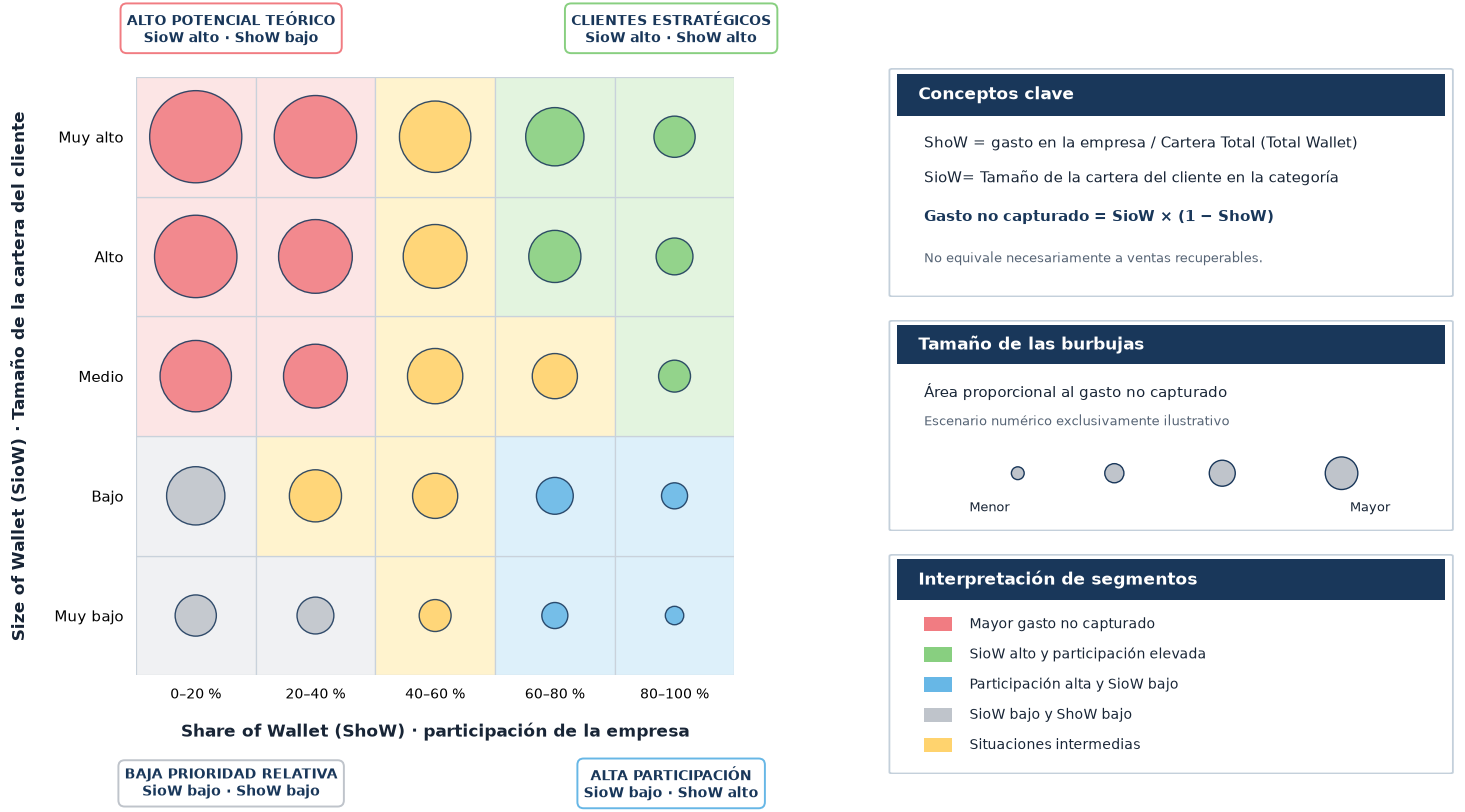

In [10]:
fig, ax = graficar_matriz_conceptual(
    potencial=potencial,
    nombre_archivo="matriz_conceptual_show_tw",
    carpeta="resultados/graficas",
    guardar=True
)

In [ ]:
from pathlib import Path

import joblib
import numpy as np
import pandas as pd

# ================================================================
# 1. CONFIGURACIÓN
# ================================================================
TAG = "_min80"

BASE = Path(
    r"../cruce_cluster_siow_sow"
)

# CAMBIAR: carpeta donde están las matrices y los IDs originales min80.
CARPETA_MATRICES = Path(
    r"../data/matrices"
)

SALIDA = Path(
    r"../data/matrices/resultados_integracion_clusters_min80"
)

WB = CARPETA_MATRICES / f"matrices_data{TAG}.xlsx"
CRUCE = (
    BASE 
    / f"cruce_clientes_clusters_sow_siow{TAG}.csv"
)
CSV_TEST = CARPETA_MATRICES / f"xgb_optuna_sow_siow_test{TAG}.csv"

MODELOS = {
    "sow": CARPETA_MATRICES / f"xgb_optuna_sow_model{TAG}.pkl",
    "siow": CARPETA_MATRICES / f"xgb_optuna_siow_model{TAG}.pkl",
}

requeridos = [
    WB, CRUCE, CSV_TEST,
    CARPETA_MATRICES / f"ids_train{TAG}.csv",
    CARPETA_MATRICES / f"ids_test{TAG}.csv",
    *MODELOS.values(),
]

faltantes = [str(p) for p in requeridos if not p.is_file()]
if faltantes:
    raise FileNotFoundError(
        "Faltan estos archivos:\n" + "\n".join(faltantes)
    )


# ================================================================
# 2. LECTURA Y VALIDACIÓN
# ================================================================
def validar_ids(df, nombre):
    if "response_id" not in df:
        raise ValueError(f"{nombre}: falta response_id")

    ids = df["response_id"]
    if ids.isna().any() or ids.eq("").any() or ids.duplicated().any():
        raise ValueError(f"{nombre}: IDs vacíos o duplicados")


def cargar_entrada(conjunto):
    ids_df = pd.read_csv(
        CARPETA_MATRICES / f"ids_{conjunto}{TAG}.csv",
        dtype={"response_id": str},
    )
    validar_ids(ids_df, conjunto)

    bloques = []
    for letra in ["V", "W"]:
        d = pd.read_excel(WB, sheet_name=f"{letra}_{conjunto}")

        # Reproduce la lectura usada por el script XGBoost.
        d = d.loc[
            :, ~d.columns.astype(str).str.lower().str.startswith("intercept")
        ]

        if len(d) != len(ids_df):
            raise ValueError(
                f"{letra}_{conjunto}: filas distintas de los IDs"
            )

        bloques.append(d.reset_index(drop=True))

    X = pd.concat(bloques, axis=1)

    if X.columns.duplicated().any():
        raise ValueError("Hay nombres de predictores duplicados")

    X = X.apply(pd.to_numeric, errors="coerce").fillna(0)

    if not np.isfinite(X.to_numpy(dtype=float)).all():
        raise ValueError("Hay predictores no finitos")

    return ids_df["response_id"].to_numpy(), X


modelos = {k: joblib.load(p) for k, p in MODELOS.items()}

resultados = {}

for conjunto in ["train", "test"]:
    ids, X = cargar_entrada(conjunto)
    pred = {}

    for variable, modelo in modelos.items():
        columnas = modelo.get_booster().feature_names

        if columnas is None:
            raise ValueError(
                f"El modelo {variable} no conserva los nombres de entrada"
            )

        ausentes = set(columnas) - set(X.columns)
        if ausentes:
            raise ValueError(
                f"Faltan variables para {variable}: {sorted(ausentes)}"
            )

        # Orden exacto utilizado por el modelo guardado.
        valores = modelo.predict(X.loc[:, columnas])

        if not np.isfinite(valores).all():
            raise ValueError(f"Predicciones inválidas de {variable}")

        # Mismos límites aplicados en el script original.
        pred[variable] = (
            np.clip(valores, 0, 1)
            if variable == "sow"
            else np.maximum(valores, 0)
        )

    resultados[conjunto] = pd.DataFrame({
        "response_id": ids,
        "SoW_pred": pred["sow"],
        "Siow_pred": pred["siow"],
    })

if set(resultados["train"].response_id) & set(resultados["test"].response_id):
    raise ValueError("TRAIN y TEST comparten clientes")


# ================================================================
# 3. VERIFICAR QUE LOS MODELOS REPRODUCEN EL TEST GUARDADO
# ================================================================
guardado = pd.read_csv(CSV_TEST, dtype={"response_id": str})
validar_ids(guardado, "CSV TEST")

nuevo = resultados["test"]

if set(guardado.response_id) != set(nuevo.response_id):
    raise ValueError("Los IDs TEST no coinciden con el CSV guardado")

comparacion = guardado.merge(
    nuevo,
    on="response_id",
    validate="one_to_one",
    suffixes=("_guardado", "_nuevo"),
)

for columna in ["SoW_pred", "Siow_pred"]:
    a = comparacion[f"{columna}_guardado"].to_numpy()
    b = comparacion[f"{columna}_nuevo"].to_numpy()

    if not np.allclose(a, b, atol=1e-5, rtol=1e-6):
        raise ValueError(
            f"{columna}: el modelo y las matrices no reproducen "
            f"el CSV TEST. Diferencia máxima: {np.max(np.abs(a-b)):.8g}"
        )

print("Verificación TEST correcta: modelos y matrices reproducen el CSV.")


# ================================================================
# 4. INCORPORAR LOS OBJETIVOS REALES DEL TRAIN POR ID
# ================================================================
cruce = pd.read_csv(CRUCE, dtype={"response_id": str})
validar_ids(cruce, "Cruce de clústeres")

if set(cruce.response_id) != set(resultados["train"].response_id):
    raise ValueError("Los clústeres no cubren exactamente el TRAIN")

referencia = cruce[
    ["response_id", "sow", "siow"]
].rename(columns={
    "sow": "SoW_real",
    "siow": "Siow_real",
})

train = resultados["train"].merge(
    referencia,
    on="response_id",
    how="left",
    validate="one_to_one",
)

train = train[
    ["response_id", "SoW_real", "SoW_pred", "Siow_real", "Siow_pred"]
]

if not np.isfinite(train.drop(columns="response_id").to_numpy()).all():
    raise ValueError("El resultado TRAIN contiene valores inválidos")

SALIDA.mkdir(parents=True, exist_ok=True)
ruta = SALIDA / f"xgb_optuna_sow_siow_train{TAG}.csv"
train.to_csv(ruta, index=False)

print(f"Predicciones TRAIN guardadas: {ruta}")
print(f"Clientes: {len(train)}")

FileNotFoundError: Faltan estos archivos:
..\cluster_tag\cluster_tag\cruce_clientes_clusters_sow_siow_min80.csv